# Procesamiento y Limpieza de Datos

Este notebook contiene el flujo estructurado para cargar, limpiar, normalizar y exportar las respuestas del estudio sobre relaciones y dinámicas de pareja. Los datos limpios se exportarán para su consumo en el dashboard final.

### Diccionario de Datos Procesados

| Columna Corta | Tipo | Descripción / Categorías Generadas |
| :--- | :--- | :--- |
| `cuenta` | Categórico | Número de cuenta normalizado (9 dígitos) |
| `tiene_pareja` | Categórico | Estado sentimental actual (`si` / `no`) |
| `edad_primera_relacion` | Numérico | Edad del primer noviazgo |
| `significado_enamoramiento` | Texto | Definición personal de estar enamorado |
| `base_confianza` | Categórico | Palabras clave detectadas para la confianza (honestidad, lealtad, etc.) |
| `definicion_respeto` | Categórico | Dimensiones de respeto identificadas |
| `cualidad_valorada` | Categórico | Tipo de cualidades valoradas (valores, conexión emocional, etc.) |
| `no_negociables` | Categórico | Conceptos clave identificados como límites insalvables |
| `red_flags` | Texto | Señales de alerta descritas |
| `diferencia_edad_max` | Numérico | Años máximos de diferencia aceptados |
| `diferencia_edad_dir` | Categórico | Dirección aceptada (`Mayores`, `Menores`, `Rango`, `Cualquiera`) |
| `demostracion_carino` | Categórico | Lenguajes del amor no verbales detectados |
| `gesto_significativo` | Categórico | Tipo de acción significativa recibida |
| `resolucion_desacuerdos` | Categórico | Estilo de resolución de conflictos |
| `cita_ideal_cat` | Categórico | Categoría macro de la cita ideal |
| `cita_ideal_sub` | Categórico | Detalles o actividades específicas de la cita |

In [1]:
# Ajuste de ruta para importar desde src/
import sys
from difflib import SequenceMatcher
from pathlib import Path
from nltk.stem import SnowballStemmer
sys.path.insert(0, str(Path("..").resolve()))

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option('display.max_colwidth', None)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
stemmer = SnowballStemmer('spanish')

## 1. Cargar datos crudos

In [2]:
import requests

SHEET_CSV_URL = "https://docs.google.com/spreadsheets/d/e/2PACX-1vQmx6xTqJDv0c-e9SAWH7Jku6ZCiIfIbSrKHHXD1oxrslbA0j3ZqpAP6pP8SXd2CmLB5WDHanazOy12/pub?gid=1639119631&single=true&output=csv"

response = requests.get(SHEET_CSV_URL)
with open('../data/raw/amor.csv', 'wb') as f:
  f.write(response.content)

df = pd.read_csv('../data/raw/amor.csv')
print(f"Shape original: {df.shape}")
df.head()

Shape original: (21, 21)


,Marca temporal,Dirección de correo electrónico,¿Deseas participar en el estudio?,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
0,12/10/2026 16:26:08,321184074@pcpuma.acatlan.unam.mx,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,30/10/2026 18:40:27,321188065@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,7.0,Si,14.0,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",+/- 2 años,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pasado y comiendo algo.,Un viaje a otro país.,Cómo si fuera la primera vez
2,30/10/2026 18:55:47,424059594@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,7.0,No,12.0,Que una persona te genere muchas emociones y no dejes de pensar en ella,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa persona,"Leal, respetuosa, cariñosa y con buen sentido del humor",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriores y que tome un papel exageradamente toxico,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar para esa persona cuando lo necesita",Escucharme hablar del mismo tema infinidad de veces,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después una cena en un lago o algo asi,La canción Mi Riqueza
3,30/10/2026 23:58:24,423085822@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,MAC,7.0,Si,15.0,Escuche Amar y querer de José José para más detalles.,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus zapatos.",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empatía.,"El que violente física, emocionalmente de mi. Aislamiento, Love bombing.",+/- 3 años,"Tener retroalimentación, pasar un rato juntos, dedicarle de mi tiempo ya sea dándoles algo o brindarles algo que me nazca.","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jugando, etc., llegar una solución y que ambos estén de acuerdo.","Simplemente estar con esa persona lo hace ideal, además de que lo mejor siempre sale de imprevisto.","Something About You de Eyedress y Dent May, recomendadísima."
4,31/10/2026 13:10:25,424000455@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,MAC,7.0,No,12.0,Que te atraiga la persona y que la acept

## 2. Exploración inicial

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 21 columns):
 #   Column                                                                                Non-Null Count  Dtype  
---  ------                                                                                --------------  -----  
 0   Marca temporal                                                                        21 non-null     str    
 1   Dirección de correo electrónico                                                       21 non-null     str    
 2   ¿Deseas participar en el estudio?                                                     21 non-null     str    
 3   ¿A qué área de conocimiento pertenece tu carrera?                                     20 non-null     str    
 4   ¿Cuál es tu carrera?                                                                  20 non-null     str    
 5   ¿En qué semestre te encuentras actualmente?                                           20 non-null 

In [4]:
# Seleccionamos la columna de quién desea participar y la de tiempo
col_participar = df.columns[2]
col_tiempo = df.columns[0]

# Mapear "Sí" → 1, "No" → 0
df[col_participar] = df[col_participar].map({"Sí": 1, "No": 0})
df = df[df[col_participar] == 1].copy()

# Eliminar columnas innecesarias
df = df.drop(columns=[col_participar, col_tiempo])

In [5]:
# Extraer números de cuenta
df = df.rename(columns={df.columns[0]: "No. Cuenta"})
col_cuenta = df.columns[0]
df[col_cuenta] = df[col_cuenta].astype(str).str.extract(r'(\d{9})')

In [6]:
display(df.describe(include='all'))

,No. Cuenta,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
count,20,20,20,20.0,20,20.000000,20,20,20,20,20,20,20,20,20,20,20,20,20
unique,20,1,12,NaN,4,NaN,20,20,20,20,20,20,20,17,20,20,19,20,20
top,321188065,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,NaN,No,NaN,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",3 años de diferencia,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablarlo,Un viaje a otro país.,Cómo si fuera la primera vez
freq,1,20,4,NaN,10,NaN,1,1,1,1,1,1,1,2,1,1,2,1,1
mean,NaN,NaN,NaN,7.0,NaN,12.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,0.0,NaN,6.189125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,7.0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,7.0,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,7.0,NaN,14.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,7.0,NaN,16.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Eliminando la columna del área de conocimiento (todos son de la 1)
# Eliminando la columna del semestre, todos son de 7mo
df = df.drop(columns=[df.columns[1], df.columns[3]])

In [8]:
# Exploración de columnas
display(df.head(10))
df.dtypes

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,Matemáticas Aplicadas y Computación,Si,14.0,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",+/- 2 años,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pasado y comiendo algo.,Un viaje a otro país.,Cómo si fuera la primera vez
2,424059594,Matemáticas Aplicadas y Computación,No,12.0,Que una persona te genere muchas emociones y no dejes de pensar en ella,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa persona,"Leal, respetuosa, cariñosa y con buen sentido del humor",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriores y que tome un papel exageradamente toxico,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar para esa persona cuando lo necesita",Escucharme hablar del mismo tema infinidad de veces,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después una cena en un lago o algo asi,La canción Mi Riqueza
3,423085822,MAC,Si,15.0,Escuche Amar y querer de José José para más detalles.,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus zapatos.",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empatía.,"El que violente física, emocionalmente de mi. Aislamiento, Love bombing.",+/- 3 años,"Tener retroalimentación, pasar un rato juntos, dedicarle de mi tiempo ya sea dándoles algo o brindarles algo que me nazca.","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jugando, etc., llegar una solución y que ambos estén de acuerdo.","Simplemente estar con esa persona lo hace ideal, además de que lo mejor siempre sale de imprevisto.","Something About You de Eyedress y Dent May, recomendadísima."
4,424000455,MAC,No,12.0,Que te atraiga la persona y que la aceptes como es,Honestidad,Que respete mis límites,Empatía,Alto,Que sea mentiroso que sea indeciso,Controlador que sea grosero,2 años más que yo,Detalles tiempo de calidad,Sorprenderme en mi cumpleaños,Hablarlo,Una cita romántica,Love Rosie
5,424144407,Matemáticas aplicadas y Computación,Si,13.0,"Para mí estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegría, cariño, y amor.","Comunicación, respeto y sinceridad","Simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educación y valores","El ser escuchado, la atención a los detalles me hace sentir que valgo","Basándome en mi pareja y patrones que he tenido 

No. Cuenta                                                                                  str
¿Cuál es tu carrera?                                                                        str
¿Tienes pareja actualmente?                                                                 str
¿A qué edad fue tu primera relación amorosa?                                            float64
¿Qué significa para ti estar enamorado?                                                     str
¿Cuál consideras que es la base de la confianza?                                            str
¿Cómo defines el respeto dentro de una relación?                                            str
¿Qué cualidad valoras más en una pareja y por qué?                                          str
Describe físicamente a tu pareja ideal                                                      str
¿Cuáles son tus "no negociables" en una relación?                                           str
¿Cuáles son las red flags (señales de al

In [9]:
nulos = df.isnull().sum()
display(nulos[nulos > 0] if nulos.sum() > 0 else "✅ No hay valores nulos en el dataset.")

'✅ No hay valores nulos en el dataset.'

## Funciones

In [10]:
def normalizar_texto(serie):
    s = serie.astype(str).str.lower()
    s = s.str.replace('á', 'a', regex=False)\
           .str.replace('é', 'e', regex=False)\
           .str.replace('í', 'i', regex=False)\
           .str.replace('ó', 'o', regex=False)\
           .str.replace('ú', 'u', regex=False)\
           .str.replace('ü', 'u', regex=False)\
           .str.replace('ñ', 'n', regex=False)
    s = s.str.replace(r'\.', '', regex=True)
    s = s.str.replace(r'\s+', ' ', regex=True).str.strip()
    return s.replace(['nan', 'nat', 'none'], pd.NA)

def normalizar_lista(serie):
    s = serie.astype(str)
    s = s.str.replace(r'\s+y\s+', ', ', regex=True)
    s = s.str.replace(r'\s*,\s*', ', ', regex=True)
    s = s.str.replace(r'\.', '', regex=True)
    s = s.str.replace(r'^,\s*', '', regex=True)\
           .str.replace(r',\s*$', '', regex=True)\
           .str.strip()
    return s.replace(['nan', 'nat', 'none', ''], pd.NA)

def mapear_carrera(texto, lista_oficial, umbral=0.75):
    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan
    mejor_coincidencia = None
    max_similitud = 0.0
    for carrera in lista_oficial:
        similitud = SequenceMatcher(None, texto, carrera.lower()).ratio()
        if similitud > max_similitud:
            max_similitud = similitud
            mejor_coincidencia = carrera
    return mejor_coincidencia if max_similitud >= umbral else texto

def limpiar_carrera(serie):
    CARRERAS_OFICIALES = [
        "actuaria", "arquitectura", "ciencia de datos", "ingenieria civil",
        "matematicas aplicadas y computacion", "ciencias politicas y administracion publica",
        "comunicacion", "derecho", "economia", "relaciones internacionales",
        "sociologia", "diseño grafico", "filosofia", "pedagogia"
    ]
    s = serie.copy()
    palabras_a_quitar = [
        r'\bingenier[ií]a\b', r'\bing\b', r'\bing\.\b',
        r'\blicenciatura\b', r'\blic\b', r'\blic\.\b',
        r'\blicenciatura en\b', r'\bcarrera\b', r'\buniversidad\b',
        r'\bunam\b', r'\bfacultad\b', r'\bfes\b'
    ]
    for patron in palabras_a_quitar:
        s = s.str.replace(patron, '', regex=True, case=False)
    s = s.str.replace(r'\s*\,\s*', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()
    mapeos_especificos = {
        'matematicas aplicadas y computacion': 'mac',
        'ingenieria civil': 'civil',
        'ciencias politicas y administracion publica': 'cpap',
        'relaciones internacionales': 'ri',
    }
    s = s.apply(lambda x: mapear_carrera(x, CARRERAS_OFICIALES, umbral=0.90))
    for viejo, nuevo in mapeos_especificos.items():
        s = s.str.replace(viejo, nuevo, regex=False, case=False)
    return s

def clasificar_por_categorias(texto, diccionario_categorias, default_val="Otro / No clasificado"):
    if pd.isna(texto) or str(texto).strip() == '':
        return default_val
    palabras = re.findall(r'\b\w+\b', str(texto).lower())
    palabras_stem = set(stemmer.stem(p) for p in palabras)
    categorias_detectadas = []
    for categoria, subcategorias in diccionario_categorias.items():
        match_encontrado = False
        if isinstance(subcategorias, dict):
            keywords_list = [kw for sub in subcategorias.values() for kw in sub]
        else:
            keywords_list = subcategorias
        for kw in keywords_list:
            kw_lower = kw.lower()
            if " " in kw_lower:
                if kw_lower in str(texto).lower():
                    match_encontrado = True
                    break
            else:
                raiz = stemmer.stem(kw_lower)
                if raiz in palabras_stem or (len(raiz) >= 5 and any(p.startswith(raiz) for p in palabras_stem)):
                    match_encontrado = True
                    break
        if match_encontrado:
            categorias_detectadas.append(categoria)
    return ", ".join(categorias_detectadas) if categorias_detectadas else default_val

## Normalizar datos

In [11]:
# Normalizar columnas de texto
cols_a_normalizar = [col for i, col in enumerate(df.columns) if i not in [0, 3]]

for col in cols_a_normalizar:
    if df[col].dtype == 'str' or df[col].dtype == 'object':
        df[col] = normalizar_texto(df[col])
# Estandarizar columnas de lista
indices_listas = [5, 8, 9, 10, 12]
cols_listas = [df.columns[i] for i in indices_listas if i < len(df.columns)]

for col in cols_listas:
    df[col] = normalizar_lista(df[col])
display(df.head(10))

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,matematicas aplicadas y computacion,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de controlar todo","frases para controlar o atacar emocionalmente a alguien querer estar 24/7 con la otra persona dependencia emocional no entender un ""no""",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez
2,424059594,matematicas aplicadas y computacion,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, falta de respeto","que me hable mucho de sus relaciones anteriores, que tome un papel exageradamente toxico",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza
3,423085822,mac,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi aislamiento, love bombing",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima"
4,424000455,mac,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,matematicas aplicadas y computacion,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante

### Limpiando la columna de carrera

In [12]:
col_carrera = df.columns[1]
df[col_carrera] = limpiar_carrera(df[col_carrera])
display(df[col_carrera].value_counts().head(20))

df = df.drop(columns=[col_carrera])

¿Cuál es tu carrera?
mac    20
Name: count, dtype: int64

## Gráficos de frecuencia

In [13]:
display(df.head(10))

,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de controlar todo","frases para controlar o atacar emocionalmente a alguien querer estar 24/7 con la otra persona dependencia emocional no entender un ""no""",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, falta de respeto","que me hable mucho de sus relaciones anteriores, que tome un papel exageradamente toxico",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi aislamiento, love bombing",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima"
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, no tener tiempo de calidad","revisar el telefono, que le “caigan mal” mis amigos, el que qui

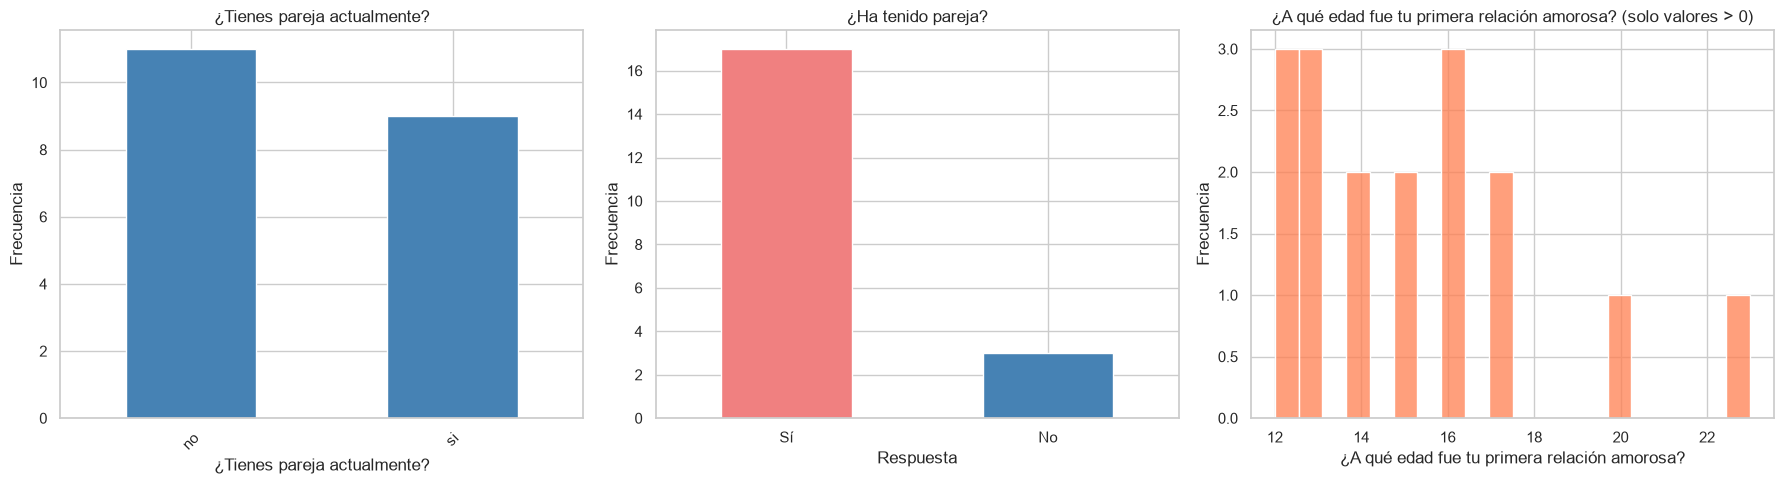

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Columna 1: Categórica (ha tenido pareja)
col_cat = df.columns[1]
counts = df[col_cat].value_counts()
counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title(f'{col_cat}')
axes[0].set_xlabel(col_cat)
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=45)

# Columna 2: Numérica (primera pareja)
col_pareja = df.columns[2]

# Función para mapear: 0 -> "No", cualquier otra cosa -> "Sí"
def clasificar_pareja(valor):
    if pd.isna(valor):
        return "No especificado"
    return "Sí" if valor != 0 else "No"

# Aplicar el mapeo y contar frecuencias
serie_pareja = df[col_pareja].apply(clasificar_pareja)
counts_pareja = serie_pareja.value_counts()

# Graficar (usamos colores distintos para Sí/No)
colores = {'Sí': 'lightcoral', 'No': 'steelblue', 'No especificado': 'gray'}
bar_colors = [colores.get(x, 'gray') for x in counts_pareja.index]

counts_pareja.plot(kind='bar', ax=axes[1], color=bar_colors)
axes[1].set_title(f'¿Ha tenido pareja?')
axes[1].set_xlabel('Respuesta')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=0)

# Columna 2: Numérica (edad) - Solo valores > 0
df_edad_filtrada = df[df[col_pareja] > 0][col_pareja]
sns.histplot(df_edad_filtrada, bins=20, ax=axes[2], color='coral')
axes[2].set_title(f'{col_pareja} (solo valores > 0)')
axes[2].set_xlabel(col_pareja)
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## Variables significativas

In [15]:
CONCEPTOS_ORIGINALES_BASE_CONFIANZA = [
    "honestidad", "confianza", "lealtad", "comunicacion",
    "vulnerable", "respeto", "sinceridad", "empatia",
    "apoyo", "comprension", "tiempo", "paciencia",
    "congruencia", "libertad", "amor", "transparencia", "responsabilidad"
]

CONCEPTOS_NO_NEGOCIABLES = [
    "honestidad", "mentira", "mentiras", "engano", "enganos", "mentiroso", "deshonestidad"
    "respeto", "falta de respeto", "maltrato",
    "lealtad", "fidelidad", "infidelidad", "traicion", "traicionar",
    "comunicacion", "silencio", "ignorar",
    "confianza", "desconfianza", "celos",
    "libertad", "espacio", "privacidad", "control", "posesividad", "asfixia",
    "empatia", "apoyo", "indiferencia", "manipulacion", "manipular",
    "tiempo", "proyecto_vida", "futuro", "hijos",
    "valores", "estabilidad", "madurez", "indeciso", "adiccion", "drogas",
    "humor", "inteligencia", "atraccion", "familia",
    "ayuda", "empatico", "respeto", "violencia"
]

DIMENSIONES_FISICAS = {
    "altura": ["alto", "altos", "bajo", "bajos", "estatura", "pequeña", "pequeño", "pequeños", "pequeñas", "grande", "gigante", "enano", "mediana", "talla", "mts", "metros", "altura"],
    "complexion": ["delgado", "delgada", "gordo", "flaco", "robusto", "atlético", "musculoso", "peso", "cuerpo", "complexión", "promedio", "figura", "silueta", "forma"],
    "cabello": ["pelo", "cabello", "lacio", "rizado", "chino", "rubio", "oscuro", "castaño", "negro", "calvo", "peluca", "melena", "coleta", "color"],
    "rostro_ojos": ["ojos", "mirada", "cara", "sonrisa", "dientes", "barba", "bigote", "lentes", "gafas", "bonito", "bella", "guapo", "facial", "faciales", "labios", "nariz", "mejillas"],
    "etnia_piel": ["moreno", "morena", "morenito", "morenita", "blanco", "asiático", "latino", "piel", "trigueño", "indígena", "raza", "etnia", "color", "tono"],
    "salud_higiene": ["sano", "saludable", "limpio", "cuidado", "arreglado", "estilo", "moda", "higiene", "extremidades", "fuerte", "fitness"],
    "sin_importancia": ["no", "me", "fijo", "importa", "irrelevante", "personalidad", "interior", "alma", "mente", "ningún", "ninguna", "rasgo", "carácter", "humor", "sentido", "inteligencia", "valores", "hay"]
}

SUBCATEGORIAS = {
    "altura": {
        "alto": ["alto", "altos", "alta", "altas", "grande", "gigante", "170"],
        "bajo": ["bajo", "bajos", "baja", "bajas", "pequeno", "pequena", "pequen", "enano"]
    },
    "cabello": {
        "rubio": ["rubio", "rubia", "blondo"],
        "castaño": ["castaño", "castaña", "cafe", "café", "marron", "moreno"],
        "negro_oscuro": ["negro", "negra", "oscura", "oscuro"],
        "claro": ["claro", "clara", "blanco"],
        "lacio": ["lacio", "lacia", "liso", "lisos"],
        "rizado": ["rizado", "rizada", "chino", "chinos", "ondulado", "curl"]
    },
    "etnia_piel": {
        "moreno": ["moreno", "morena", "morenito", "morenita", "trigueño"],
        "asiatico": ["asiatico", "asiática", "oriental"],
        "blanco": ["blanco", "blanca", "caucasico"]
    },
    "complexion": {
        "delgado": ["delgado", "delgada", "flaco", "flaca", "esbelto"],
        "robusto": ["robusto", "gordo", "gorda", "grueso", "musculoso", "atletico"],
        "promedio": ["promedio", "media", "medio", "normal"]
    },
    "rostro_ojos": {
        "lentes": ["lentes", "gafas"],
        "ojos_claros": ["claros", "claro", "azul", "verde"],
        "ojos_oscuros": ["oscuros", "oscuro", "cafe", "negro"],
        "sonrisa": ["sonrisa", "dientes", "sonriente", "sonriente"]
    }
}

In [16]:
CONCEPTOS_BASE_CONFIANZA = {
    stemmer.stem(palabra): palabra
    for palabra in CONCEPTOS_ORIGINALES_BASE_CONFIANZA
}
CONCEPTOS_NO_NEGOCIABLES = {
    stemmer.stem(palabra): palabra
    for palabra in CONCEPTOS_NO_NEGOCIABLES
}

In [17]:
def extraer_conceptos_clave(texto, CONCEPTOS_OBJETIVO):
    palabras = re.findall(r'\b\w+\b', str(texto).lower())
    palabras_stem = [stemmer.stem(p) for p in palabras]
    encontrados = []
    for raiz, palabra_original in CONCEPTOS_OBJETIVO.items():
        if raiz in palabras_stem:
            encontrados.append(palabra_original)
    return ", ".join(encontrados) if encontrados else pd.NA

def clasificar_fisico(texto):
    palabras = re.findall(r'\b\w+\b', str(texto).lower())
    palabras_stem = set(stemmer.stem(p) for p in palabras)
    keywords_sin_imp = [stemmer.stem(k) for k in DIMENSIONES_FISICAS["sin_importancia"]]
    matches_sin_imp = sum(1 for raiz in keywords_sin_imp if raiz in palabras_stem)
    if matches_sin_imp >= 2:
        return "No relevante / Personalidad", pd.NA
    categorias_detectadas = []
    for categoria, keywords in DIMENSIONES_FISICAS.items():
        if categoria == "sin_importancia":
            continue
        keywords_stem = [stemmer.stem(k) for k in keywords]
        if any(raiz in palabras_stem for raiz in keywords_stem):
            categorias_detectadas.append(categoria)
    if not categorias_detectadas:
        return "Otro / No especificado", pd.NA
    subcategorias_detectadas = []
    for categoria in categorias_detectadas:
        if categoria in SUBCATEGORIAS:
            for subcat_nombre, subcat_keywords in SUBCATEGORIAS[categoria].items():
                subcat_stem = [stemmer.stem(k) for k in subcat_keywords]
                if any(raiz in palabras_stem for raiz in subcat_stem):
                    subcategorias_detectadas.append(f"{categoria}:{subcat_nombre}")
    categoria_str = ", ".join(categorias_detectadas)
    subcategoria_str = ", ".join(subcategorias_detectadas) if subcategorias_detectadas else pd.NA
    return categoria_str, subcategoria_str

def clasificar_cita_ideal(texto):
    """
    Clasifica respuestas de citas ideales en temáticas claras.
    """
    palabras = re.findall(r'\b\w+\b', texto)
    palabras_stem = set(stemmer.stem(p) for p in palabras)

    categorias, subcategorias = [], []

    for categoria, subcats in CATEGORIAS_CITA.items():
        for subcat, keywords in subcats.items():
            encontrado = False
            for kw in keywords:
                kw_lower = kw.lower()
                # Frases de varias palabras -> búsqueda directa en el texto
                if " " in kw_lower:
                    if kw_lower in texto:
                        encontrado = True
                        break
                else:
                    raiz = stemmer.stem(kw_lower)
                    # Match exacto de raíz, o por prefijo solo si la raíz es >= 5 chars
                    if raiz in palabras_stem or (
                        len(raiz) >= 5 and any(p.startswith(raiz) for p in palabras_stem)
                    ):
                        encontrado = True
                        break
            if encontrado:
                if categoria not in categorias:
                    categorias.append(categoria)
                subcategorias.append(f"{subcat}")

    if categorias:
        return ", ".join(categorias), " | ".join(subcategorias)
    return "Otro / No clasificado", "Otro / No clasificado"

In [18]:
col_original = df.columns[4]

df[f"{col_original}"] = df[col_original].apply(
    lambda x: extraer_conceptos_clave(
        x if pd.notna(x) else "",
        CONCEPTOS_BASE_CONFIANZA
    )
)
display(display(df.iloc[:, [0, 4]].head(10)))

,No. Cuenta,¿Cuál consideras que es la base de la confianza?
1,321188065,"honestidad, confianza"
2,424059594,"honestidad, lealtad"
3,423085822,"comunicacion, vulnerable"
4,424000455,honestidad
5,424144407,"comunicacion, respeto, sinceridad"
6,321339968,"comunicacion, respeto"
7,424038010,"honestidad, confianza, respeto"
8,422032861,"honestidad, comunicacion"
9,424047638,"honestidad, comunicacion"
10,422085764,"honestidad, comunicacion"


None

In [19]:
col_original = df.columns[8]

df[f"{col_original}"] = df[col_original].apply(
    lambda x: extraer_conceptos_clave(
        x if pd.notna(x) else "",
        CONCEPTOS_NO_NEGOCIABLES
    )
)
display(display(df.iloc[:, [8]].head(30)))

,"¿Cuáles son tus ""no negociables"" en una relación?"
1,"mentiroso, enganos, infidelidad, control"
2,"infidelidad, respeto"
3,"infidelidad, empatia, manipular"
4,"mentiroso, indeciso"
5,"infidelidad, tiempo"
6,"espacio, privacidad"
7,adiccion
8,"infidelidad, respeto"
9,"confianza, ayuda"
10,"lealtad, confianza, respeto"


None

In [20]:
col_fisico = df.columns[7]
df[[f"{col_fisico}_CATEGORIA", f"{col_fisico}_DETALLE"]]= df[col_fisico].apply(
    lambda x: pd.Series(clasificar_fisico(x))
)

display(display(df.iloc[:, [-1, -2]].head(30)))
df.drop(columns=[col_fisico])

,Describe físicamente a tu pareja ideal _DETALLE,Describe físicamente a tu pareja ideal _CATEGORIA
1,NaN,No relevante / Personalidad
2,NaN,No relevante / Personalidad
3,altura:bajo,altura
4,altura:alto,altura
5,"altura:alto, complexion:promedio, etnia_piel:moreno","altura, complexion, etnia_piel"
6,etnia_piel:asiatico,etnia_piel
7,NaN,No relevante / Personalidad
8,NaN,"altura, rostro_ojos"
9,NaN,"cabello, rostro_ojos"
10,NaN,No relevante / Personalidad


None

,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?",Describe físicamente a tu pareja ideal _CATEGORIA,Describe físicamente a tu pareja ideal _DETALLE
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz","mentiroso, enganos, infidelidad, control","frases para controlar o atacar emocionalmente a alguien querer estar 24/7 con la otra persona dependencia emocional no entender un ""no""",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez,No relevante / Personalidad,NaN
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"infidelidad, respeto","que me hable mucho de sus relaciones anteriores, que tome un papel exageradamente toxico",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza,No relevante / Personalidad,NaN
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos","infidelidad, empatia, manipular","el que violente fisica, emocionalmente de mi aislamiento, love bombing",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima",altura,altura:bajo
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,"mentiroso, indeciso",controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie,altura,altura:alto
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","infidelidad, tiempo","revisar el telefono, que le “caigan mal” mis amigos, el que quiera tener life 360, el que me quiera dar “explicaciones” de todo cuando no son necesarias (nerviosismos raros cuando no son necesarios)",-2/+4 anos de diferencia

In [21]:
def limpiar_diferencia_edad(texto):
    if any(p in texto for p in ["+/-", "-/+", "no importa", "indiferente", "da igual", "cualquiera"]):
        numeros = re.findall(r'\d+', texto)
        maximo = max(int(n) for n in numeros) if numeros else "Indefinido"
        return maximo, "Cualquiera"

    if texto in ["+", "+ anos"]:
        return "Indefinido", "Mayores"

    # 3. Extraer solo los números (\d+ encuentra cualquier grupo de dígitos)
    matches = re.findall(r'([+-]?)\s*(\d+)', texto)

    if not matches:
        return "Revisar", "No especificada"

    # Tomamos el número más alto como la "diferencia máxima"
    numeros_enteros = [int(m[1]) for m in matches]
    maximo = max(numeros_enteros)
    signo_max = ""
    for signo, num_str in matches:
        if int(num_str) == maximo:
            signo_max = signo
            break
    es_rango = bool(re.search(r'\d+\s*-\s*\d+', texto))

    if "mayor" in texto or "mas que" in texto or "más que" in texto:
        direccion = "Mayores"
    elif "o menos" in texto:
        direccion = "Mayores"
    elif "menor" in texto or "menos que" in texto:
        direccion = "Menores"
    elif es_rango:  # ← PRIORIDAD: Si es patrón "num-num", es Rango (ignora el signo '-' del regex)
        direccion = "Rango"
    elif signo_max == '+':
        direccion = "Mayores"
    elif signo_max == '-':
        direccion = "Menores"
    else:
        direccion = "No especificada"

    return maximo, direccion

In [22]:
col_edad = df.columns[9]
df[[f"{col_edad}_MAGNITUD", f"{col_edad}_DIRECCION"]] = df[col_edad].apply(
    lambda x: pd.Series(limpiar_diferencia_edad(x))
)
display(df.iloc[:, [-1, -2]].head(30))
df.drop(columns=[col_edad])

,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_DIRECCION,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_MAGNITUD
1,No especificada,24
2,No especificada,Revisar
3,No especificada,Revisar
4,No especificada,Revisar
5,No especificada,360
6,No especificada,Revisar
7,No especificada,Revisar
8,No especificada,Revisar
9,No especificada,Revisar
10,No especificada,Revisar


,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?",Describe físicamente a tu pareja ideal _CATEGORIA,Describe físicamente a tu pareja ideal _DETALLE,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_MAGNITUD,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_DIRECCION
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz",no me fijo fisicamente en alguien,"mentiroso, enganos, infidelidad, control",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez,No relevante / Personalidad,NaN,24,No especificada
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, respeto",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza,No relevante / Personalidad,NaN,Revisar,No especificada
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos",de baja estatura,"infidelidad, empatia, manipular",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima",altura,altura:bajo,Revisar,No especificada
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,alto,"mentiroso, indeciso",2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie,altura,altura:alto,Revisar,No especificada
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, tiempo",-2/+4 anos de diferencia,"tiempo de calidad, pequenos detalles, poder ser graciosos entre 

In [23]:
CATEGORIAS_CARINO = {
    "Contacto físico": [
        "abraz", "bes", "carici", "toc", "mano", "piel", "acurruc", "contacto", "mimo", "apretar", "fisic"
    ],
    "Tiempo de calidad": [
        "tiemp", "escuch", "atencion", "atenc", "mirar", "ojo", "compañi", "estar", "presente", "acompañ", "caminar", "junt"
    ],
    "Actos de servicio": [
        "cocin", "ayud", "cuid", "hacer", "servir", "prepar", "arregl", "limpi", "llevar", "traer", "aliment", "comida", "brind", "ofrec"
    ],
    "Regalos y detalles": [
        "regal", "sorpres", "flores", "obsequi", "detall", "nota", "carta"
    ],
    "Apoyo emocional": [
        "apoy", "comprend", "comprension", "pacienci", "consuel", "anim", "calmar", "tranquil", "seguridad", "necesit", "retroaliment"
    ],
    "Diversión y complicidad": [
        "gracios", "divert", "reir", "risa", "broma", "complici", "carism", "jugar", "jueg", "sonris"
    ]
}

CATEGORIAS_CITA = {
    "Gastronomía / Comida": {
        "cena": ["cenar", "cena", "cenita"],
        "desayuno": ["desayuno", "desayunar", "brunch"],
        "restaurante": ["restaurante", "restaurant"],
        "café": ["cafe", "cafeteria"],
        "comida casual": ["taco", "pizza", "hamburguesa", "sushi", "helado", "postre", "antojito", "comer", "comida"],
        "cocinar juntos": ["cocinar", "cocina", "hornear", "preparar"],
        "bar / bebidas": ["bar", "cantina", "vino", "cerveza", "coctel", "trago"],
        "picnic": ["picnic", "canasta"],
    },
    "Aire libre / Naturaleza": {
        "playa / mar": ["playa", "mar", "arena", "olas"],
        "parque / jardín": ["parque", "jardin", "plaza"],
        "bosque / montaña / lago": ["bosque", "montana", "lago", "rio", "cascada", "senderismo", "camping", "cabana"],
        "atardecer / estrellas": ["atardecer", "amanecer", "estrellas", "luna", "mirador"],
    },
    "Entretenimiento / Cultura": {
        "cine / películas": ["cine", "pelicula", "pelis", "film"],
        "videojuegos": ["videojuego", "videojuegos", "xbox", "playstation", "nintendo", "consola", "jugar"],
        "música / concierto": ["concierto", "musica", "karaoke", "banda"],
        "museo / arte / teatro": ["museo", "galeria", "arte", "exposicion", "teatro", "obra"],
        "libros / lectura": ["libro", "libreria", "leer", "lectura"],
        "baile / fiesta": ["bailar", "baile", "discoteca", "antro"],
        "juegos / feria": ["boliche", "billar", "arcade", "feria", "diversiones", "juegos de mesa"],
    },
    "Privacidad": {
        "en casa": ["casa", "sofa", "sillon", "cama", "dormir", "netflix", "serie"],
        "a solas / sin interrupciones": ["solos", "solas", "privacidad", "intimidad", "intimo",
                                        "vacio", "interrumpir", "interrupciones", "prejuicios",
                                        "nosotros", "conociendonos", "ella y yo", "solo nosotros",
                                        "tranquilo", "tranquila", "pocas personas", "sin gente",
                                        "no hayan muchas", "no haya mucha"],
        "cualquier lugar con la persona": ["cualquier lugar", "donde sea", "no importa el lugar",
                                           "mientras sea con", "solo que este", "con ella", "con el",
                                           "con esa persona"],
        "lugar significativo": ["signifique algo", "especial para", "importante para", "significativo"],
        "compartir un momento": ["juntos", "momento", "compartir", "compania", "estar",
                                 "platicar", "charlar", "conversar", "hablar", "hablar horas",
                                 "abrazado", "abrazos", "mimos", "reir", "reír", "risas"],
    },
    "Paseos": {
        "paseo en auto": ["paseo en auto", "pasear en auto", "paseo en carro", "ruta en auto",
                          "manejar", "conducir", "dar una vuelta"],
        "caminata": ["caminar", "caminata", "andar", "callejear", "dar un paseo"],
        "bicicleta": ["bici", "bicicleta"],
    },
    "Aventura / Viaje": {
        "viaje / escapada": ["viajar", "viaje", "escapada", "roadtrip", "carretera", "pueblear"],
        "explorar": ["explorar", "descubrir", "aventura", "turistear"],
    },
    "Actividad física": {
        "deporte / gym": ["deporte", "gym", "gimnasio", "futbol", "basquet", "nadar", "correr"],
        "patinar": ["patinar", "patines"],
    },
    "Espontaneidad / Imprevisto": {
        "plan sorpresa / improvisado": ["imprevisto", "improvisar", "sorpresa", "sorprender",
                                       "espontaneo", "inesperado", "sin plan", "lo que surja",
                                       "cosas que nos gusten", "lo que nos guste"],
    },
}

CATEGORIAS_DESACUERDO = {
    "Comunicación directa": {
        "hablar/dialogar": ["hablar", "dialogar", "conversar", "platicar", "comunicar", "expresar"],
        "ser honesto": ["honestidad", "honesto", "sinceridad", "sincero", "claro", "directo"],
        "sin gritos": ["sin gritar", "tranquilo", "calma", "calmado", "pacifico", "sin pelear"],
    },
    "Espacio y tiempo": {
        "darse tiempo": ["tiempo", "espacio", "enfriar", "calmar", "pensar", "reflexionar"],
        "no inmediato": ["despues", "luego", "mas tarde", "no inmediato", "esperar"],
    },
    "Empatía y comprensión": {
        "escuchar": ["escuchar", "oír", "atencion", "ojo"],
        "entender al otro": ["entender", "comprender", "ponerse en su lugar", "empatia", "perspectiva"],
        "validar sentimientos": ["validar", "aceptar", "reconocer sentimientos", "no juzgar"],
    },
    "Disculpa y reparación": {
        "pedir perdón": ["perdon", "disculpa", "disculparme", "arrepentir", "reconocer error"],
        "reparar el daño": ["reparar", "arreglar", "compensar", "mejorar"],
    },
    "Colaboración y negociación": {
        "buscar solución juntos": ["solucion", "resolver", "llegar a un acuerdo", "negociar", "acuerdo"],
        "compromiso": ["compromiso", "ceder", "transar", "medio camino"],
    },
    "Evitación": {
        "ignorar/evitar": ["ignorar", "evitar", "no hablar", "dejar pasar", "olvidar", "hacer como si nada"],
        "distanciamiento": ["alejarse", "distanciarse", "no verse", "tomar distancia"],
    },
}

CATEGORIAS_CUALIDADES = {
    "Valores éticos": {
        "honestidad": ["honestidad", "honesto", "sinceridad", "sincero", "verdad", "transparente"],
        "lealtad": ["lealtad", "leal", "fidelidad", "fiel"],
        "integridad": ["integridad", "integro", "coherencia", "congruente", "principios"],
        "respeto": ["respeto", "respetuoso", "respetar"],
        "autenticidad": ["autentico", "genuino", "real", "verdadero", "sin mascaras", "sin filtro", "como es"],
    },
    "Conexión emocional": {
        "empatía y escucha": ["empatia", "empatico", "comprension", "comprender", "entender",
                              "escuchar", "escuchado", "escucha", "oír"],
        "cariño/afecto": ["carino", "cariñoso", "afecto", "afectuoso", "ternura", "dulce"],
        "apoyo incondicional": ["apoyo", "apoyar", "respaldo", "soporte", "estar ahi", "ahi para mi", "siempre esta"],
        "paciencia": ["paciencia", "paciente", "tolerancia"],
    },
    "Conexión intelectual y social": {
        "humor": ["humor", "gracioso", "divertido", "buen sentido del humor", "alegre"],
        "inteligencia": ["inteligencia", "inteligente", "cultura", "sabiduria", "listo"],
        "comunicación": ["comunicacion", "comunicativo", "dialogo", "hablar", "hablar las cosas"],
        "sociabilidad": ["extrovertido", "extrovertida", "sociable", "social"],
    },
    "Carácter y madurez": {
        "madurez": ["madurez", "maduro", "responsabilidad", "responsable"],
        "seguridad": ["seguridad", "seguro", "confianza en si mismo", "autoestima"],
        "perseverancia": ["perseverancia", "perseverante", "resiliencia", "resiliente", "no rendirse", "nunca se rinda", "esfuerzo"],
        "humildad": ["humildad", "humilde", "no orgullosa", "sin orgullo"],
        "independencia": ["independencia", "independiente", "autonomo", "libertad"],
    },
    "Compatibilidad": {
        "valores compartidos": ["valores", "principios", "creencias", "moral", "etica"],
        "proyecto de vida": ["proyecto de vida", "futuro", "metas comunes", "objetivos"],
        "intereses comunes": ["intereses", "gustos", "hobbies", "aficiones", "pasatiempos"],
    },
    "Atracción y química": {
        "atracción física": ["atraccion", "atractivo", "belleza", "guapo", "hermoso", "fisico"],
        "química": ["quimica", "conexion", "chispa", "flechazo"],
    },
}

CATEGORIAS_RESPETO = {
    "Espacio y autonomía": {
        "libertad personal": ["libertad", "libre", "independencia", "independiente", "autonomia"],
        "no controlar": ["no controlar", "sin control", "no ser controlador", "no posesivo", "no celoso"],
        "tiempo personal": ["tiempo propio", "espacio personal", "mi tiempo", "su espacio", "soledad"],
        "decisiones propias": ["decidir", "decisiones", "elegir", "elecciones", "propios criterios"],
    },
    "Opinión y pensamiento": {
        "escuchar al otro": ["escuchar", "oír", "atencion", "escucha"],
        "no imponer": ["no imponer", "sin imponer", "no forzar opinion", "no obligar"],
        "aceptar diferencias": ["diferencias", "pensar diferente", "opiniones distintas", "no juzgar", "aceptar"],
        "validar sentimientos": ["validar", "sentimientos", "emociones", "reconocer", "importan"],
        "comunicación": ["comunicacion", "comunicar", "asertiva", "asertivo", "dialogo", "hablar"],
    },
    "Cuerpo y límites físicos": {
        "consentimiento": ["consentimiento", "consentir", "no forzar", "no presionar"],
        "respeto al cuerpo": ["cuerpo", "fisico", "limites fisicos", "intimidad", "sexual"],
        "no agresión": ["no golpear", "no pegar", "sin violencia", "no agredir", "no lastimar", "lastimar"],
        "límites generales": ["limites", "límites", "fronteras", "emocional", "emocionalmente", "poner limites"]
    },
    "Tiempo y compromiso": {
        "puntualidad": ["puntual", "tiempo", "hora", "llegar a tiempo", "no hacer esperar"],
        "valorar el tiempo": ["valorar tiempo", "respetar tiempo", "no desperdiciar", "aprovechar"],
        "cumplir promesas": ["promesa", "palabra", "cumplir", "compromiso", "coherencia"],
    },
    "Individualidad y autenticidad": {
        "ser uno mismo": ["ser uno mismo", "como es", "autentico", "genuino", "sin mascaras", "natural"],
        "no cambiar al otro": ["no cambiar", "aceptar como es", "no modificar", "no intentar cambiar"],
        "respetar gustos e ideales": ["gustos", "hobbies", "intereses", "pasatiempos", "preferencias", "ideales", "apoyo de ideales"]
    },
    "Relaciones externas": {
        "respeto a familia": ["familia", "padres", "hermanos", "familiares"],
        "respeto a amigos": ["amigos", "amistades", "amigas", "circulo social"],
        "no aislar": ["no aislar", "no alejar", "no separar", "relaciones externas"],
    },
    "Trato digno": {
        "sin gritos ni insultos": ["sin gritar", "no gritar", "sin insultos", "no insultar", "sin humillar", "no humillar"],
        "amabilidad": ["amable", "amabilidad", "cortesia", "educacion", "buen trato", "tratarse bien"],
        "igualdad": ["igual", "igualdad", "equidad", "pareja", "equitativo", "50 50"],
        "dignidad": ["dignidad", "digno", "reconociendo", "reconocer"]
    },
    "Confianza y cuidado mutuo": {
        "honestidad": ["honestidad", "honesto", "sinceridad", "sincero", "verdad", "transparente"],
        "no engañar": ["no engañar", "sin engañar", "no mentir", "sin mentiras", "no traicionar", "infieles", "infidelidad"],
        "lealtad": ["lealtad", "leal", "fidelidad", "fiel"],
        "confianza y cuidado": ["confianza", "confiar", "corresponder", "cuidar", "cuidado", "sanamente", "respetar todo"]
    },
}

CATEGORIAS_SIGNIFICATIVO = {
    "Apoyo en momentos difíciles": {
        "salud / cuidado": ["enfermo", "enfermedad", "hospital", "doctor", "cuidar", "cuido", "medicina", "cuidado", "cuidarme"],
        "crisis emocional": ["crisis", "mal momento", "depresion", "ansiedad", "triste", "llorar", "duelo", "perdida", "etapa dificil", "dificil", "momento dificil"],
        "problemas económicos": ["dinero", "economico", "deuda", "pagar", "prestamo", "trabajo", "empleo", "problemas"],
    },
    "Presencia y compañía": {
        "estar ahí": ["estar ahi", "acompañar", "compania", "no me dejo solo", "solo"],
        "escucha y atención": ["escuchar", "escucha", "hablar", "desahogarme", "consejo", "atencion", "atender", "compartir tiempo", "tiempo juntos", "dedicar tiempo"],
        "dar su tiempo": ["su tiempo", "tiempo conmigo", "regalar tiempo", "regalado su tiempo", "darme tiempo", "dar tiempo", "tiempo para mi"], # ← NUEVO: captura "regalar tiempo" y variantes
    },
    "Detalles y gestos de amor": {
        "sorpresas / regalos": ["sorpresa", "regalo", "detalle", "flores", "carta", "obsequio", "cumpleaños", "cumple"],
        "servicios cotidianos": ["cocinar", "desayuno", "comida", "limpiar", "ayudar en casa"],
    },
    "Apoyo en metas y sueños": {
        "estudios / carrera": ["estudios", "universidad", "tesis", "carrera", "aprender", "estudiar", "estudio", "oportunidad de estudiar"],
        "proyectos personales": ["proyecto", "sueños", "metas", "emprender", "negocio", "creer en mi"],
    },
    "Perdón y lealtad": {
        "perdonar errores": ["perdonar", "perdon", "segunda oportunidad", "otra oportunidad", "error"],
        "defender / proteger": ["defender", "proteger", "respaldar", "lealtad"],
    },
    "Aceptación incondicional": {
        "amar como soy": ["incondicional", "aceptar", "como soy", "sin juzgar", "defectos", "cambiar"],
    },
}


In [24]:
col_carino = df.columns[9]
df[f"{col_carino}"] = df[col_carino].apply(lambda x: clasificar_por_categorias(x, CATEGORIAS_CARINO))
display(df.iloc[:, [9]].head(30))

,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?
1,Tiempo de calidad
2,Otro / No clasificado
3,Contacto físico
4,Otro / No clasificado
5,Otro / No clasificado
6,Actos de servicio
7,Otro / No clasificado
8,Otro / No clasificado
9,Otro / No clasificado
10,Otro / No clasificado


In [25]:
col_cita = df.columns[12]
df[[f"{col_cita}_CATEGORIA", f"{col_cita}_SUBCATEGORIA"]] = df[col_cita].apply(
    lambda x: pd.Series(clasificar_cita_ideal(x))
)
display(df.iloc[:, [12, -1, -2]].head(30))

,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA,¿Qué es lo más significativo que alguien ha hecho por ti?_CATEGORIA
1,tratarme como una persona normal y ser paciente,comida casual,Gastronomía / Comida
2,escucharme hablar del mismo tema infinidad de veces,compartir un momento,Privacidad
3,"que sean materialistas, detallistas y escuchen",Otro / No clasificado,Otro / No clasificado
4,sorprenderme en mi cumpleanos,plan sorpresa / improvisado,Espontaneidad / Imprevisto
5,"demostrarme que no estoy sola, sin quitarme mi “independencia” pero hacerme saber y demostrar que si algo ni va del todo bien el estara para mi apoyandome (cuando es necesario)",a solas / sin interrupciones | compartir un momento,Privacidad
6,en general atencion-,Otro / No clasificado,Otro / No clasificado
7,cocinarme,cocinar juntos,Gastronomía / Comida
8,escucharme y apoyarme cuando tengo problemas,Otro / No clasificado,Otro / No clasificado
9,compartir su tiempo conmigo,compartir un momento,Privacidad
10,estar ahi,compartir un momento,Privacidad


In [26]:
col_desacuerdo = df.columns[11]
df[f"{col_desacuerdo}"] = df[col_desacuerdo].apply(lambda x: clasificar_por_categorias(x, CATEGORIAS_DESACUERDO))
display(df.iloc[:, [11, -1]].head(30))

,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA
1,Espacio y tiempo,comida casual
2,Espacio y tiempo,compartir un momento
3,Espacio y tiempo,Otro / No clasificado
4,Espacio y tiempo,plan sorpresa / improvisado
5,Espacio y tiempo,a solas / sin interrupciones | compartir un momento
6,Otro / No clasificado,Otro / No clasificado
7,Otro / No clasificado,cocinar juntos
8,Empatía y comprensión,Otro / No clasificado
9,Espacio y tiempo,compartir un momento
10,Espacio y tiempo,compartir un momento


In [27]:
col_cualidad = df.columns[6]
df[f"{col_cualidad}"] = df[col_cualidad].apply(lambda x: clasificar_por_categorias(x, CATEGORIAS_CUALIDADES))
display(df.iloc[:, [6, -1]].head(30))

,¿Qué cualidad valoras más en una pareja y por qué?,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA
1,Conexión emocional,comida casual
2,Conexión emocional,compartir un momento
3,Conexión intelectual y social,Otro / No clasificado
4,Conexión emocional,plan sorpresa / improvisado
5,Conexión emocional,a solas / sin interrupciones | compartir un momento
6,Conexión intelectual y social,Otro / No clasificado
7,"Valores éticos, Carácter y madurez",cocinar juntos
8,Valores éticos,Otro / No clasificado
9,"Valores éticos, Conexión emocional",compartir un momento
10,"Valores éticos, Carácter y madurez",compartir un momento


In [28]:
col_respeto = df.columns[5]
df[f"{col_respeto}"] = df[col_respeto].apply(lambda x: clasificar_por_categorias(x, CATEGORIAS_RESPETO))
display(df.iloc[:, [5, -1]].head(30))

,¿Cómo defines el respeto dentro de una relación?,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA
1,"Opinión y pensamiento, Cuerpo y límites físicos",comida casual
2,Confianza y cuidado mutuo,compartir un momento
3,Otro / No clasificado,Otro / No clasificado
4,Cuerpo y límites físicos,plan sorpresa / improvisado
5,"Trato digno, Confianza y cuidado mutuo",a solas / sin interrupciones | compartir un momento
6,Trato digno,Otro / No clasificado
7,Confianza y cuidado mutuo,cocinar juntos
8,Cuerpo y límites físicos,Otro / No clasificado
9,"Opinión y pensamiento, Cuerpo y límites físicos, Trato digno",compartir un momento
10,Individualidad y autenticidad,compartir un momento


In [29]:
col_significativo = df.columns[10]
df[f"{col_significativo}"] = df[col_significativo].apply(lambda x: clasificar_por_categorias(x, CATEGORIAS_SIGNIFICATIVO))
display(df.iloc[:, [10, -1]].head(30))

,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA
1,Otro / No clasificado,comida casual
2,Otro / No clasificado,compartir un momento
3,Otro / No clasificado,Otro / No clasificado
4,Otro / No clasificado,plan sorpresa / improvisado
5,Otro / No clasificado,a solas / sin interrupciones | compartir un momento
6,Otro / No clasificado,Otro / No clasificado
7,Otro / No clasificado,cocinar juntos
8,Otro / No clasificado,Otro / No clasificado
9,Otro / No clasificado,compartir un momento
10,Otro / No clasificado,compartir un momento


# Union

In [30]:
df.head()

,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?",Describe físicamente a tu pareja ideal _CATEGORIA,Describe físicamente a tu pareja ideal _DETALLE,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_MAGNITUD,¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_DIRECCION,¿Qué es lo más significativo que alguien ha hecho por ti?_CATEGORIA,¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza","Opinión y pensamiento, Cuerpo y límites físicos",Conexión emocional,no me fijo fisicamente en alguien,"mentiroso, enganos, infidelidad, control",Tiempo de calidad,Otro / No clasificado,Espacio y tiempo,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez,No relevante / Personalidad,NaN,24,No especificada,Gastronomía / Comida,comida casual
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",Confianza y cuidado mutuo,Conexión emocional,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, respeto",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza,No relevante / Personalidad,NaN,Revisar,No especificada,Privacidad,compartir un momento
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, vulnerable",Otro / No clasificado,Conexión intelectual y social,de baja estatura,"infidelidad, empatia, manipular",Contacto físico,Otro / No clasificado,Espacio y tiempo,"que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima",altura,altura:bajo,Revisar,No especificada,Otro / No clasificado,Otro / No clasificado
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,Cuerpo y límites físicos,Conexión emocional,alto,"mentiroso, indeciso",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie,altura,altura:alto,Revisar,No especificada,Espontaneidad / Imprevisto,plan sorpresa / improvisado
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","Trato digno, Confianza y cuidado mutuo",Conexión emocional,"basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, tiempo",Otro / No clasificado,Otro / No clasifica

In [31]:
# Renombrar las columnas finales de acuerdo con las etiquetas cortas del diccionario de datos
df.columns = [re.sub(r'\s+', ' ', col).strip() for col in df.columns]

mapeo_columnas_cortas = {
    'No. Cuenta': 'cuenta',
    '¿Tienes pareja actualmente?': 'tiene_pareja',
    '¿A qué edad fue tu primera relación amorosa?': 'edad_primera_relacion',
    '¿Qué significa para ti estar enamorado?': 'significado_enamoramiento',
    '¿Cuál consideras que es la base de la confianza?': 'base_confianza',
    '¿Cómo defines el respeto dentro de una relación?': 'definicion_respeto',
    '¿Qué cualidad valoras más en una pareja y por qué?': 'cualidad_valorada',
    'Describe físicamente a tu pareja ideal': 'pareja_ideal_fisico',
    '¿Cuáles son tus "no negociables" en una relación?': 'no_negociables',
    '¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?': 'red_flags',
    '¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?': 'diferencia_edad_max',
    '¿Cómo demuestras cariño sin usar palabras?': 'demostracion_carino',
    '¿Qué es lo más significativo que alguien ha hecho por ti?': 'gesto_significativo',
    '¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?': 'resolucion_desacuerdos',
    'Describe brevemente una cita ideal, sin importar presupuesto ni lugar.': 'cita_ideal',
    '¿Qué canción, película o libro describe mejor tu idea del amor?': 'referencia_amor',
    'Describe físicamente a tu pareja ideal _CATEGORIA': 'pareja_ideal_fisico_cat',
    'Describe físicamente a tu pareja ideal _DETALLE': 'pareja_ideal_fisico_sub',
    '¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_MAGNITUD': 'red_flags_magnitud',
    '¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_DIRECCION': 'red_flags_direccion',
    '¿Qué es lo más significativo que alguien ha hecho por ti?_CATEGORIA': 'gesto_significativo_cat',
    '¿Qué es lo más significativo que alguien ha hecho por ti?_SUBCATEGORIA': 'gesto_significativo_sub'
}

df = df.rename(columns=mapeo_columnas_cortas)
display(df.head(5))

,cuenta,tiene_pareja,edad_primera_relacion,significado_enamoramiento,base_confianza,definicion_respeto,cualidad_valorada,pareja_ideal_fisico,no_negociables,red_flags,diferencia_edad_max,demostracion_carino,gesto_significativo,resolucion_desacuerdos,cita_ideal,referencia_amor,pareja_ideal_fisico_cat,pareja_ideal_fisico_sub,red_flags_magnitud,red_flags_direccion,gesto_significativo_cat,gesto_significativo_sub
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza","Opinión y pensamiento, Cuerpo y límites físicos",Conexión emocional,no me fijo fisicamente en alguien,"mentiroso, enganos, infidelidad, control",Tiempo de calidad,Otro / No clasificado,Espacio y tiempo,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez,No relevante / Personalidad,NaN,24,No especificada,Gastronomía / Comida,comida casual
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",Confianza y cuidado mutuo,Conexión emocional,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, respeto",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza,No relevante / Personalidad,NaN,Revisar,No especificada,Privacidad,compartir un momento
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, vulnerable",Otro / No clasificado,Conexión intelectual y social,de baja estatura,"infidelidad, empatia, manipular",Contacto físico,Otro / No clasificado,Espacio y tiempo,"que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima",altura,altura:bajo,Revisar,No especificada,Otro / No clasificado,Otro / No clasificado
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,Cuerpo y límites físicos,Conexión emocional,alto,"mentiroso, indeciso",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie,altura,altura:alto,Revisar,No especificada,Espontaneidad / Imprevisto,plan sorpresa / improvisado
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","Trato digno, Confianza y cuidado mutuo",Conexión emocional,"basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, tiempo",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,"demostrarme que no estoy sola, sin quitarme mi “independencia” pero hacerme saber y demostrar que si algo ni va del todo bien el estara para mi apoyandome (cuando es necesario)",hablando las veces y tiempo que sea necesario el tema hasta que las dos partes esten en el mismo punto,un dia de picnic,off campus,"altura, complexion, etnia_piel","altura:alto, complexion:promedio, etnia_piel:moreno",360,No especificada,Privacidad,a solas / sin interrupciones | compartir un momento


### Importando género

In [32]:
df_genero = pd.read_csv('../data/raw/genero.csv', usecols=[2, 3])
df_genero.columns = ['cuenta', 'genero']
df["cuenta"] = df["cuenta"].astype(str).str.strip()
df_genero["cuenta"] = df_genero["cuenta"].astype(str).str.strip()
df_genero['genero'] = df_genero['genero'].astype(str).str.strip().str.lower().str.replace(".","")
mapeo_genero = {
    'm': 'Masculino',
    'masculino': 'Masculino',
    'hombre': 'Masculino',
    'f': 'Femenino',
    'femenino': 'Femenino',
    'mujer': 'Femenino',
    'otro': 'Otro',
    'no binario': 'No Binario',
    'prefiero no decirlo': 'No especificado',
    'nan': np.nan
}
df_genero['genero'] = df_genero['genero'].map(mapeo_genero).fillna('No especificado')
df_genero = df_genero.drop_duplicates(subset='cuenta', keep='last')
print(df_genero['genero'].value_counts(dropna=False))
df = pd.merge(df, df_genero[['cuenta', 'genero']], on='cuenta', how='left')

genero
Masculino    17
Femenino      7
Name: count, dtype: int64


In [35]:
df.info()
df.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   cuenta                     20 non-null     str    
 1   tiene_pareja               20 non-null     str    
 2   edad_primera_relacion      20 non-null     float64
 3   significado_enamoramiento  20 non-null     str    
 4   base_confianza             19 non-null     str    
 5   definicion_respeto         20 non-null     str    
 6   cualidad_valorada          20 non-null     str    
 7   pareja_ideal_fisico        20 non-null     str    
 8   no_negociables             19 non-null     str    
 9   red_flags                  20 non-null     str    
 10  diferencia_edad_max        20 non-null     str    
 11  demostracion_carino        20 non-null     str    
 12  gesto_significativo        20 non-null     str    
 13  resolucion_desacuerdos     20 non-null     str    
 14  cita_id

,cuenta,tiene_pareja,edad_primera_relacion,significado_enamoramiento,base_confianza,definicion_respeto,cualidad_valorada,pareja_ideal_fisico,no_negociables,red_flags,diferencia_edad_max,demostracion_carino,gesto_significativo,resolucion_desacuerdos,cita_ideal,referencia_amor,pareja_ideal_fisico_cat,pareja_ideal_fisico_sub,red_flags_magnitud,red_flags_direccion,gesto_significativo_cat,gesto_significativo_sub,genero
0,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza","Opinión y pensamiento, Cuerpo y límites físicos",Conexión emocional,no me fijo fisicamente en alguien,"mentiroso, enganos, infidelidad, control",Tiempo de calidad,Otro / No clasificado,Espacio y tiempo,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez,No relevante / Personalidad,NaN,24,No especificada,Gastronomía / Comida,comida casual,Masculino
1,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",Confianza y cuidado mutuo,Conexión emocional,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, respeto",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza,No relevante / Personalidad,NaN,Revisar,No especificada,Privacidad,compartir un momento,Masculino
2,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, vulnerable",Otro / No clasificado,Conexión intelectual y social,de baja estatura,"infidelidad, empatia, manipular",Contacto físico,Otro / No clasificado,Espacio y tiempo,"que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima",altura,altura:bajo,Revisar,No especificada,Otro / No clasificado,Otro / No clasificado,Masculino
3,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,Cuerpo y límites físicos,Conexión emocional,alto,"mentiroso, indeciso",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie,altura,altura:alto,Revisar,No especificada,Espontaneidad / Imprevisto,plan sorpresa / improvisado,Femenino
4,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","Trato digno, Confianza y cuidado mutuo",Conexión emocional,"basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, tiempo",Otro / No clasificado,Otro / No clasificado,Espacio y tiempo,"demostrarme que no estoy sola, sin quitarme mi “independencia” pero hacerme saber y demostrar que si algo ni va del todo bien el estara para mi apoyandome (cuando es necesario)",hablando las veces y tiempo que sea necesario el tema hasta que las dos partes esten en el mismo punto,un dia de picnic,off campus,"altura, complexion, etnia_piel","altura:alto, complexion:promedio, etnia_piel:moreno",360,No especificada,Privacidad,a solas / sin interrupciones | compartir un momento,Femenino


## Quitando variables innecesarias

In [36]:
df = df.drop(columns=df.columns[[3, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,19]])

## 5. Exportar datos limpios

In [38]:
# Definición de rutas y exportación
PROCESSED_DIR = Path("../data/processed").resolve()
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_CSV = PROCESSED_DIR / "datos_limpios_amor.csv"

df.to_csv(PROCESSED_CSV, index=False)
print(f"✓ Datos limpios guardados en: {PROCESSED_CSV}")
print(f"  Filas: {len(df)}")
print(f"  Columnas: {len(df.columns)}")

✓ Datos limpios guardados en: C:\Users\ahang\OneDrive\Escritorio\Sistemas Inteligentes\LimpiezaData\data\processed\datos_limpios_amor.csv
  Filas: 20
  Columnas: 10
